In [ ]:
# Quant Project 2: Linear Regression Modeling for predicting the Stock P
# Step 1: Download the data from Yahoo Finance
# Step 2: Some Feature Engineering (to build new features) - Technical In
# Step 3: Run Linear Regression Model
# Step 4: Check how the model is performed (Actual vs Predicted)
# Step 5: Test for all the assumptions
# Step 6: Check the prediction


In [2]:
# !pip install yfinance

In [1]:
# Import all the packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import yfinance as yf

In [2]:
# Step 1: Download the data from Yahoo Finance
tickers = ['AAPL', 'AMZN', 'MSFT', 'QQQ', '^GSPC']
df = yf.download(tickers, start = '2020-01-01', end = '2024-12-31')['Close']
df

[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,MSFT,QQQ,^GSPC
Date,,,,,
2020-01-02,72.333885,94.900497,151.829544,208.088867,3257.850098
2020-01-03,71.630646,93.748497,149.939011,206.182800,3234.850098
2020-01-06,72.201401,95.143997,150.326584,207.511276,3246.280029
2020-01-07,71.861862,95.343002,148.955948,207.482346,3237.179932
2020-01-08,73.017830,94.598503,151.328552,209.041901,3253.050049
...,...,...,...,...,...
2024-12-23,253.649414,225.059998,430.147217,519.006104,5974.069824
2024-12-24,256.560822,229.050003,434.179321,526.043640,6040.040039
2024-12-26,257.375580,227.050003,432.973663,525.686401,6037.589844


In [3]:
# Step 2: Perform Feature Engineering

# Considering Yesterday's Value
df['AAPL(t-1)'] = df['AAPL'].shift(1)
df['AMZN(t-1)'] = df['AMZN'].shift(1)
df['MSFT(t-1)'] = df['MSFT'].shift(1)
df['QQQ(t-1)'] = df['QQQ'].shift(1)
df['^GSPC(t-1)'] = df['^GSPC'].shift(1)
# Moving Avg (MA): Technical Indicator 
df['AAPL_MA_5'] = df['AAPL'].rolling(window=5).mean()
df['AMZN_MA_5'] = df['AMZN'].rolling(window=5).mean()
df['MSFT_MA_5'] = df['MSFT'].rolling(window=5).mean()
df['QQQ_MA_5'] = df['QQQ'].rolling(window=5).mean()
df['^GSPC_MA_5'] = df['^GSPC'].rolling(window=5).mean()
# Set Y Variable - Next day
df['Target'] = df['AAPL'].shift(-1)
df = df.dropna()


In [4]:
df.columns

Index(['AAPL', 'AMZN', 'MSFT', 'QQQ', '^GSPC', 'AAPL(t-1)', 'AMZN(t-1)',
       'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5',
       'MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5', 'Target'],
      dtype='str', name='Ticker')

In [6]:
# Step 3: Fit a Linear Regression Model
# Set X and Y variable for Linear Regression Model - Ordinary Least Squares (OLS)
import statsmodels.api as sm
X = df[['AAPL(t-1)', 'AMZN(t-1)',
 'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5',
 'MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5']]
Y = df['Target']
X_const = sm.add_constant(X) # Intercept Term
# Train the Model
model = sm.OLS(Y, X_const).fit()
# Summary
model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Target   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                 1.644e+04
Date:                Sun, 09 Aug 2026   Prob (F-statistic):               0.00
Time:                        15:29:47   Log-Likelihood:                -3379.0
No. Observations:                1252   AIC:                             6780.
Df Residuals:                    1241   BIC:                             6836.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5089      1.141      0.446      0.656      -1.730       2.748
AAPL(t-1)      0.4682      0.081      5.764      0.000       0.309       0.628
AMZN(t-1)      0.0644      0.067      0.958      0.338      -0.067       0.196
MSFT(t-1)     -0.0165      0.053     -0.314      0.753      -0.120       0.087
QQQ(t-1)       0.0091      0.102      0.089      0.929      -0.190       0.208
^GSPC(t-1)     0.0053      0.007      0.734      0.463      -0.009       0.019
AAPL_MA_5      0.5158      0.082      6.279      0.000       0.355       0.677
AMZN_MA_5     -0.0591      0.068     -0.866      0.386      -0.193       0.075
MSFT_MA_5      0.0282      0.053      0.531      0.595      -0.076       0.132
QQQ_MA_5      -0.0099      0.104     -0.096      0.924      -0.214       0.194
^GSPC_MA_5    -0.0056      0.007     -0.776      0.438      -0.020       0.009
==============================================================================
Omnibus:                       26.037   Durbin-Watson:                   0.808
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               49.707
Skew:                          -0.085   Prob(JB):                     1.61e-11
Kurtosis:                       3.961   Cond. No.                     6.88e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.88e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [7]:
# P value < 0.05 = Variable is significant => Keep that variable
# P value > 0.05 = Variable is not significant => Drop that variable

In [8]:
# Set X and Y variable for Linear Regression Model - Ordinary Least Squa
import statsmodels.api as sm
X = df[['AAPL(t-1)', '^GSPC(t-1)']] # Dropping AAPL_MA_5
Y = df['Target']
X_const = sm.add_constant(X) # Intercept Term
# Train the Model
model = sm.OLS(Y, X_const).fit()
# Summary
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Target   R-squared:                       0.992
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                 7.762e+04
Date:                Sun, 09 Aug 2026   Prob (F-statistic):               0.00
Time:                        15:30:54   Log-Likelihood:                -3418.4
No. Observations:                1252   AIC:                             6843.
Df Residuals:                    1249   BIC:                             6858.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.7159      0.747     -0.959      0.338      -2.181       0.749
AAPL(t-1)      0.9840      0.007    140.621      0.000       0.970       0.998
^GSPC(t-1)     0.0008      0.000      2.114      0.035    5.79e-05       0.002
==============================================================================
Omnibus:                       40.864   Durbin-Watson:                   1.041
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              103.863
Skew:                          -0.036   Prob(JB):                     2.80e-23
Kurtosis:                       4.409   Cond. No.                     3.08e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.08e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [9]:
df_train_predict = pd.DataFrame()
df_train_predict['Actual'] = df['Target']
df_train_predict['Predicted'] = model.predict(X_const)
df_train_predict


,Actual,Predicted
Date,,
2020-01-08,74.568794,72.599272
2020-01-09,74.737358,73.749512
2020-01-10,76.334091,75.293078
2020-01-13,75.303337,75.451429
2020-01-14,74.980598,77.040941
...,...,...
2024-12-20,253.649414,248.235803
2024-12-23,256.560822,252.882566
2024-12-24,257.375580,253.679957


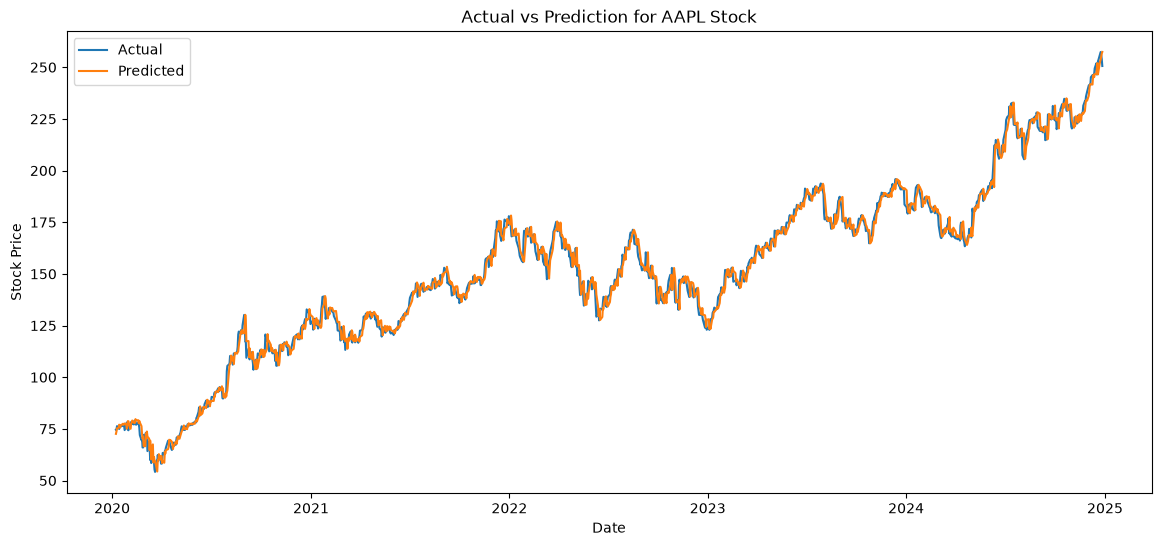

In [ ]:
# Plot between Actual vs Predicted Value
# Initialize the plot size
plt.figure(figsize=(14, 6))

# Plot actual vs predicted values with completed labels and quotes
plt.plot(df_train_predict.index, df_train_predict['Actual'], label='Actual')
plt.plot(df_train_predict.index, df_train_predict['Predicted'], label='Predicted')

# Add titles, labels, and display the legend
plt.title("Actual vs Prediction for AAPL Stock")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()  # Added to display the 'Actual' and 'Predicted' labels

# Render the plot
plt.show()


In [12]:
# Catch is: We need to still test LR Assumptions
# We need to check how the model is performing on test data


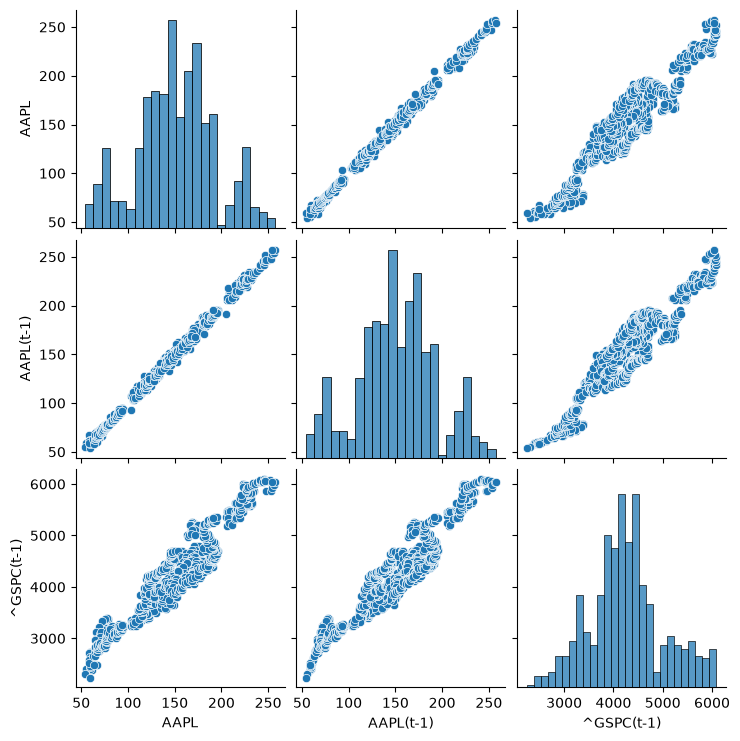

In [13]:
# Assumptions of Linear Regression:
# 1) Linearity between dependent and independent variable - Met
import seaborn as sns
df = df[['AAPL', 'AAPL(t-1)', '^GSPC(t-1)']]
sns.pairplot(df)
# AAPL & AAPL(t-1) has linear relationship
# AAPL & S&P500 has linear relationship
# AAPL & AAPL_MA_5 has linear relationship

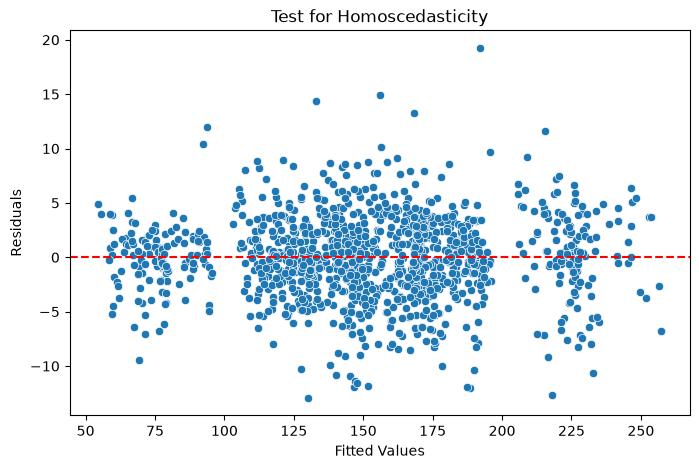

In [14]:
# 2) Homoscedasticity: Fitting Residual with the predicted value
residual = model.resid # Actual - Predicted
fitted = model.fittedvalues # Predicted Y Value
plt.figure(figsize = (8,5))
sns.scatterplot(x = fitted, y = residual)
plt.axhline(0, color = 'red', linestyle = '--')
plt.title('Test for Homoscedasticity')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.show()
# Since it's a tube like structure => It is homoscedastic -> Assumption i
# If it was funnel like structure => It is heteroscedastic


In [15]:
X_const.columns

Index(['const', 'AAPL(t-1)', '^GSPC(t-1)'], dtype='str')

In [ ]:
# 3) Multicollinearity => VIF (Variance Inflation Factor) => For independent variables
# Rule of thumb for VIF
# VIF < 1 => No Multicollinearity
# VIF < 10 => Moderate Multicollinearity
# VIF > 10 => Strong Multicollinearity
# VIF = Condition is Met

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Initialize an empty DataFrame for VIF results
vif = pd.DataFrame()
vif['Features'] = X_const.columns

# Calculate VIF for each feature using a list comprehension
vif['VIF'] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

# Drop the constant/intercept row (index 0) if you only want to see independent variables
vif = vif[1:]
vif


,Features,VIF
1,AAPL(t-1),7.634911
2,^GSPC(t-1),7.634911


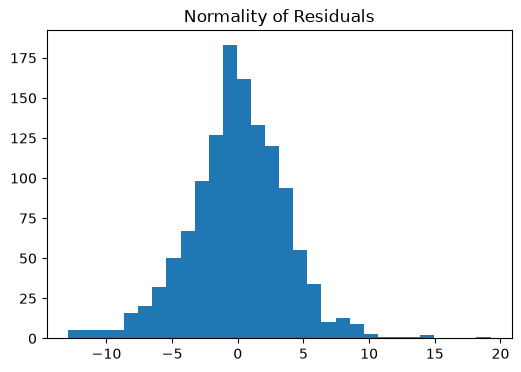

In [18]:
# 4) Assumption: Normality of Residual => 1) Visual Test (Histogram) or Q-Q Plot
plt.figure(figsize = (6,4))
plt.hist(residual, bins = 30)
plt.title("Normality of Residuals")
plt.show()


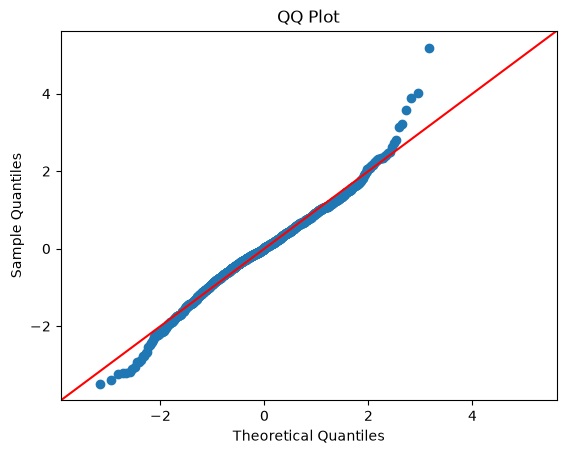

In [19]:
# QQ Plot for testing Normality of Residuals
import statsmodels.api as sm
sm.qqplot(residual, line = '45', fit = True)
plt.title('QQ Plot')
plt.show()


In [20]:
# Test 5: Auto correlation of Residual: Durbin Watson Test
from statsmodels.stats.stattools import durbin_watson
dw = durbin_watson(residual)
dw # p value
# p value < 0.05 => Autocorrelation b/w residual is there
# p value > 0.05 => Autocorrelation b/w residual is not there
# Our 5th condition is met

np.float64(1.0410070748431093)

In [21]:
# All the 5 conditions of Linear Regression Modela are met
# Linearity
# Homoscedasticity
# VIF
# Normality of Residuals
# Auto correlation of Residual


In [22]:
# Predict the Stock Price for the Year 2025

In [23]:
# Step 1: Download the data from Yahoo Finance
tickers = ['AAPL', '^GSPC']
df = yf.download(tickers, start = '2025-01-01', end = '2025-03-31')['Close']
df.head()

[*********************100%***********************]  2 of 2 completed


Ticker,AAPL,^GSPC
Date,,
2025-01-02,242.301941,5868.549805
2025-01-03,241.815033,5942.470215
2025-01-06,243.444595,5975.379883
2025-01-07,240.672318,5909.029785
2025-01-08,241.159210,5918.250000


In [24]:
# Step 2: Data Eng
df['AAPL(t-1)'] = df['AAPL'].shift(1)
df['^GSPC(t-1)'] = df['^GSPC'].shift(1)
df = df.dropna()
df.head()

Ticker,AAPL,^GSPC,AAPL(t-1),^GSPC(t-1)
Date,,,,
2025-01-03,241.815033,5942.470215,242.301941,5868.549805
2025-01-06,243.444595,5975.379883,241.815033,5942.470215
2025-01-07,240.672318,5909.029785,243.444595,5975.379883
2025-01-08,241.159210,5918.250000,240.672318,5909.029785
2025-01-10,235.346359,5827.040039,241.159210,5918.250000


In [25]:
X_test = df[['AAPL(t-1)', '^GSPC(t-1)']]
X_test = sm.add_constant(X_test)
df_result = pd.DataFrame()
df_result['Actual'] = df['AAPL']
df_result['Predicted'] = model.predict(X_test)
df_result.head()


,Actual,Predicted
Date,,
2025-01-03,241.815033,242.429123
2025-01-06,243.444595,242.009430
2025-01-07,240.672318,243.639389
2025-01-08,241.159210,240.858104
2025-01-10,235.346359,241.344623


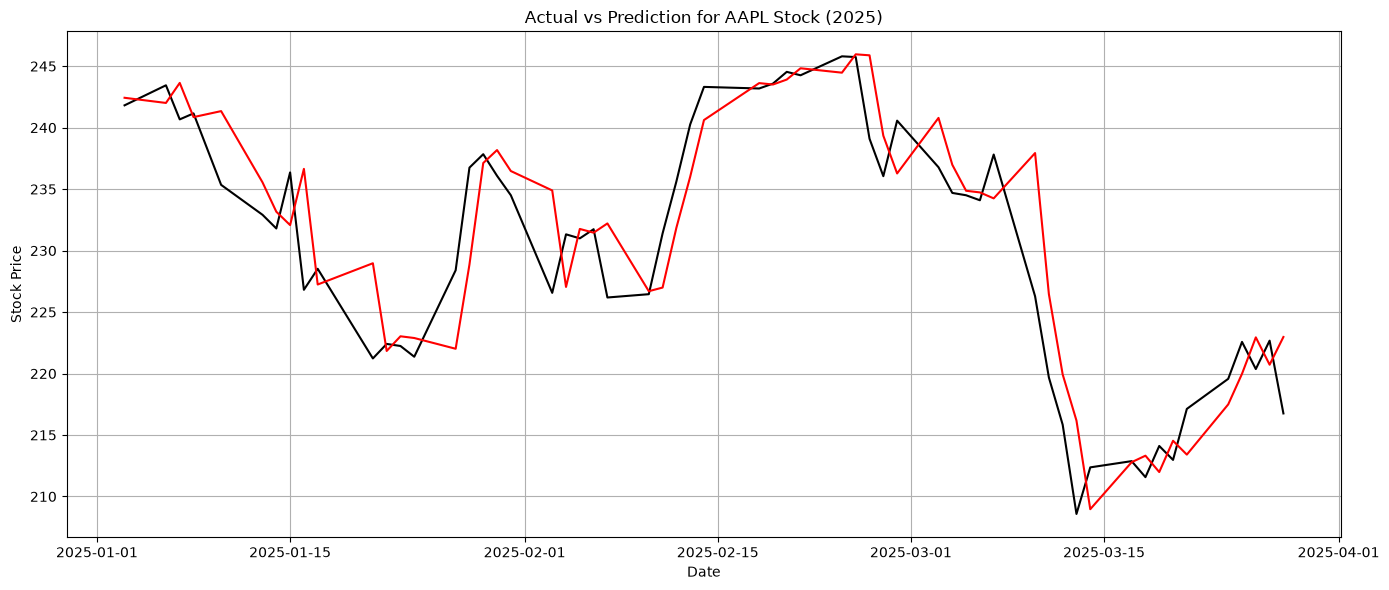

In [26]:
# Plot between Actual vs Predicted Value
import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_result.index, df_result['Actual'], label = 'Actual', color = 'black')
plt.plot(df_result.index, df_result['Predicted'], label = 'Predicted', color = 'red')
plt.title("Actual vs Prediction for AAPL Stock (2025)")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
# Risk Metrics
# Calculate rmse and mse
# rmse = root mean square error => Sq root(Avg((A - P)^2))
# mse = mean square error => Avg((A - P)^2)
from sklearn.metrics import mean_squared_error
import numpy as np
# Calculate mse
mse = mean_squared_error(df_result['Actual'], df_result['Predicted'])
rmse = np.sqrt(mse)
print(rmse, mse)


4.143709852811147 17.170331344284183


In [28]:
# Conclusion: It's a decent Model but not 100% Accurate
# Lesson: Stock data in general have lot of non linearities
# It's extremely tough to use simple linear regression model just to capature the stock price movement

# Thank You

In [3]:
# Step 1: Download the data from Yahoo Finance
tickers = ['AAPL', 'AMZN', 'MSFT', 'QQQ', '^GSPC']
df = yf.download(tickers, start = '2020-01-01', end = '2025-04-01')['Close']
df

[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,MSFT,QQQ,^GSPC
Date,,,,,
2020-01-02,72.333885,94.900497,151.829544,208.088837,3257.850098
2020-01-03,71.630630,93.748497,149.938980,206.182816,3234.850098
2020-01-06,72.201424,95.143997,150.326569,207.511276,3246.280029
2020-01-07,71.861839,95.343002,148.955948,207.482391,3237.179932
2020-01-08,73.017815,94.598503,151.328522,209.041916,3253.050049
...,...,...,...,...,...
2025-03-25,222.573975,205.710007,391.310242,490.543884,5776.649902
2025-03-26,220.365646,201.130005,386.170807,481.517517,5712.200195
2025-03-27,222.673462,201.360001,386.774872,478.773834,5693.310059


In [4]:
# Step 2: Perform Feature Engineering
# Lesson: To predict AAPL Stock price, we have to consider yesterday's price.
# The market is not open yet so we don't know what's the price today
# Considering Yesterday's Value
df['AAPL(t-1)'] = df['AAPL'].shift(1)
df['AMZN(t-1)'] = df['AMZN'].shift(1)
df['MSFT(t-1)'] = df['MSFT'].shift(1)
df['QQQ(t-1)'] = df['QQQ'].shift(1)
df['^GSPC(t-1)'] = df['^GSPC'].shift(1)
# Moving Avg (MA): Technical Indicator - It helps you understand the short-term trends
df['AAPL_MA_5'] = df['AAPL'].rolling(window=5).mean()
df['AMZN_MA_5'] = df['AMZN'].rolling(window=5).mean()
df['MSFT_MA_5'] = df['MSFT'].rolling(window=5).mean()
df['QQQ_MA_5'] = df['QQQ'].rolling(window=5).mean()
df['^GSPC_MA_5'] = df['^GSPC'].rolling(window=5).mean()
# Set Y Variable - Next day
df['Target'] = df['AAPL'].shift(-1)
df = df.dropna()
df

Ticker,AAPL,AMZN,MSFT,QQQ,^GSPC,AAPL(t-1),AMZN(t-1),MSFT(t-1),QQQ(t-1),^GSPC(t-1),AAPL_MA_5,AMZN_MA_5,MSFT_MA_5,QQQ_MA_5,^GSPC_MA_5,Target
Date,,,,,,,,,,,,,,,,
2020-01-08,73.017815,94.598503,151.328522,209.041916,3253.050049,71.861839,95.343002,148.955948,207.482391,3237.179932,72.209119,94.746899,150.475912,207.661447,3245.842041,74.568802
2020-01-09,74.568802,95.052498,153.219086,210.813202,3274.699951,73.017815,94.598503,151.328522,209.041916,3253.050049,72.656102,94.777299,150.753821,208.206320,3249.212012,74.737366
2020-01-10,74.737366,94.157997,152.510178,210.274109,3265.350098,74.568802,95.052498,153.219086,210.813202,3274.699951,73.277449,94.859200,151.268060,209.024579,3255.312012,76.334099
2020-01-13,76.334099,94.565002,154.343994,212.700012,3288.129883,74.737366,94.157997,152.510178,210.274109,3265.350098,74.103984,94.743401,152.071545,210.062326,3263.681982,75.303322
2020-01-14,75.303322,93.472000,153.256927,211.862534,3283.149902,76.334099,94.565002,154.343994,212.700012,3288.129883,74.792281,94.369200,152.931741,210.938354,3272.875977,74.980614
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-24,219.569855,203.259995,389.250549,487.760406,5767.569824,217.122772,196.210007,387.448273,477.286682,5667.560059,215.069626,196.556000,384.719122,477.827020,5677.594043,222.573975
2025-03-25,222.573975,205.710007,391.310242,490.543884,5776.649902,219.569855,203.259995,389.250549,487.760406,5767.569824,217.269998,199.134000,387.024438,481.729144,5709.991992,220.365646
2025-03-26,220.365646,201.130005,386.170807,481.517517,5712.200195,222.573975,205.710007,391.310242,490.543884,5776.649902,218.521390,200.252002,387.450238,482.565375,5717.374023,222.673462


In [ ]:
# Lasso Regression Model
# Step 1: Import all the required libraries
# Step 2: Define Features and Target Variables
# Step 3: Train Test Split
# Step 4: Apply Lasso Regression
# Step 5: Get Intercept and Coeff for Lasso Regression
# Step 6: Predict using Lasso Regression
# Step 7: Create a dataframe with Actual and Predicted Values
# Step 8: Plot Actual & Predicted Values
# Step 9: Evaluate the Model - R square, mse, rmse




In [5]:
# Step 1: Import all the required libraries
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error


In [6]:
# Step 2: Define Features and Target Variables
X = df[['AAPL(t-1)', 'AMZN(t-1)',
 'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5','MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5']]
Y = df['Target']




In [8]:
# Step 3: Train Test Split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.05,shuffle = False)

In [9]:
# Step 4: Apply Lasso Regression
from sklearn.linear_model import Lasso
lasso = Lasso(alpha = 10)
lasso.fit(X_train, Y_train) # Train the mode

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [12]:
# Step 5: Get Intercept and Coeff for Lasso Regression
coefficients = lasso.coef_
coefficients
intercept = lasso.intercept_
intercept
coeff_df = pd.DataFrame({'Feature':X.columns, 'Coefficients':coefficients})
coeff_df


,Feature,Coefficients
0,AAPL(t-1),0.572312
1,AMZN(t-1),-0.000000
2,MSFT(t-1),0.005801
3,QQQ(t-1),0.000000
4,^GSPC(t-1),0.002486
5,AAPL_MA_5,0.367647
6,AMZN_MA_5,-0.000000
7,MSFT_MA_5,0.000000
8,QQQ_MA_5,0.000000
9,^GSPC_MA_5,0.000000


In [13]:
# Step 6: Predict using Lasso Regression
y_pred = lasso.predict(X_test)
y_pred

array([248.14636141, 251.2842802 , 252.17239344, 254.82749028,
       255.70448066, 253.37722073, 250.90352569, 248.76082707,
       243.83118914, 242.98991807, 243.30024936, 240.95324985,
       240.7559423 , 236.51562453, 234.27879296, 233.33270181,
       235.21490796, 229.20680639, 229.49867596, 224.76182271,
       224.59410388, 224.18037649, 223.61254163, 228.50441706,
       234.62620467, 236.17101651, 236.05281339, 234.93768611,
       229.85704042, 232.19358253, 231.75057606, 231.63498002,
       228.27012617, 228.54405651, 231.71465834, 234.70590754,
       238.78383833, 241.7486859 , 242.6147786 , 243.56348136,
       244.35041806, 244.06887278, 245.04081601, 244.5721249 ,
       240.15780089, 237.86813322, 240.04598265, 236.75503085,
       235.0443264 , 235.02365589, 234.30509805, 235.72084186,
       227.55642985, 222.30012779, 218.31038461, 212.06425921,
       213.59548618, 213.38046613, 212.32735277, 214.27778091,
       213.94195406, 216.84519296, 219.313722  , 221.52

In [14]:
# Step 7: Create a dataframe with Actual and Predicted Values
df_result = pd.DataFrame({'Actual': Y_test, 'Predicted': y_pred})
df_result


,Actual,Predicted
Date,,
2024-12-20,253.649414,248.146361
2024-12-23,256.560791,251.284280
2024-12-24,257.375580,252.172393
2024-12-26,253.967377,254.827490
2024-12-27,250.598907,255.704481
...,...,...
2025-03-24,222.573975,216.845193
2025-03-25,220.365646,219.313722
2025-03-26,222.673462,221.527605


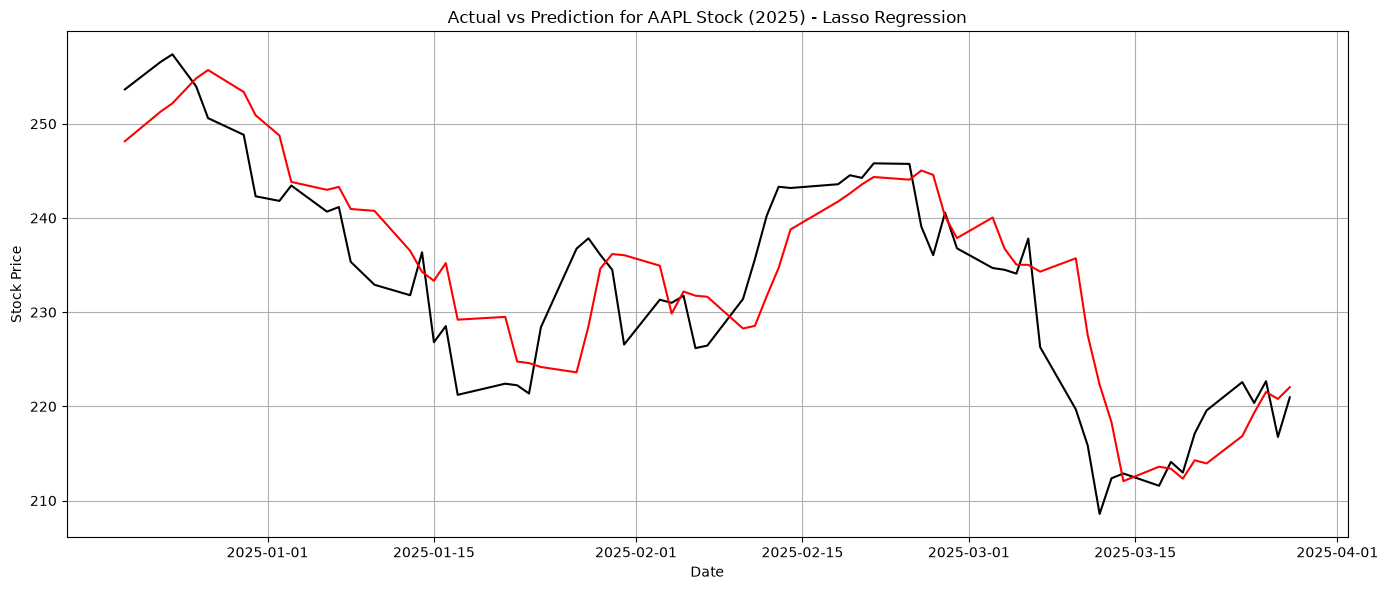

In [15]:
# Step 8: Plot Actual & Predicted Values
import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_result.index, df_result['Actual'], label = 'Actual', color = 'black')
plt.plot(df_result.index, df_result['Predicted'], label = 'Predicted', color = 'red')
plt.title("Actual vs Prediction for AAPL Stock (2025) - Lasso Regression")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.grid(True)
plt.tight_layout()
plt.show()


In [16]:
# Step 9: Evaluate the Model - R square, mse, rmse
from sklearn.metrics import r2_score, mean_squared_error
r2 = r2_score(Y_test, y_pred)
print("R square", r2)
mse = mean_squared_error(Y_test, y_pred)
print("mse",mse)
rmse = np.sqrt(mse)
print("rmse", rmse)


R square 0.7598183700966012
mse 33.61809095779083
rmse 5.798110981844935


In [ ]:
# Ridge Regression
# Step 1: Import all the required libraries
# Step 2: Define Features and Target Variables
# Step 3: Train Test Split
# Step 4: Apply Ridge Regression
# Step 5: Get Intercept and Coeff for Ridge Regression
# Step 6: Predict using Ridge Regression
# Step 7: Create a dataframe with Actual and Predicted Values
# Step 8: Plot Actual & Predicted Values
# Step 9: Evaluate the Model - R square, mse, rmse

In [17]:
# Step 1: Import all the required libraries
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error


In [18]:
# Step 2: Define Features and Target Variables
X = df[['AAPL(t-1)', 'AMZN(t-1)',
 'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5','MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5']]
Y = df['Target']




In [19]:
# Step 3: Train Test Split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.05,shuffle = False)

In [20]:
# Step 4: Apply Ridge Regression
from sklearn.linear_model import Ridge
ridge = Ridge(alpha = 10)
ridge.fit(X_train, Y_train) # Train the model


,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' t

In [21]:
# Step 5: Get Intercept and Coeff for Lasso Regression
coefficients = ridge.coef_
coefficients
intercept = ridge.intercept_
intercept
coeff_df = pd.DataFrame({'Feature':X.columns, 'Coefficients':coefficients})
coeff_df


,Feature,Coefficients
0,AAPL(t-1),0.450888
1,AMZN(t-1),0.054095
2,MSFT(t-1),-0.017371
3,QQQ(t-1),0.034689
4,^GSPC(t-1),0.004573
5,AAPL_MA_5,0.532342
6,AMZN_MA_5,-0.049278
7,MSFT_MA_5,0.029263
8,QQQ_MA_5,-0.035708
9,^GSPC_MA_5,-0.004909


In [23]:
# Step 6: Predict using Ridge Regression
y_pred = ridge.predict(X_test)
y_pred


array([248.34885844, 251.62715204, 252.85687867, 255.700119  ,
       256.36090399, 253.99268605, 251.54424151, 249.19117765,
       244.70604185, 244.05252211, 244.1726368 , 241.20292015,
       240.76770816, 236.6447757 , 234.59195575, 233.59297569,
       235.14226042, 229.53164141, 229.43592022, 225.34079366,
       224.42051386, 223.65941045, 223.06017981, 227.17879196,
       233.11017223, 234.8771895 , 235.95879271, 234.88099414,
       230.19699786, 232.03372672, 231.18391509, 230.99377947,
       227.46516077, 228.20186063, 230.92874814, 233.48854581,
       237.80675404, 240.9006822 , 242.04320785, 243.13199383,
       243.84403237, 243.31244228, 244.22148345, 243.87342502,
       240.5885717 , 237.88135108, 240.04750614, 236.3882021 ,
       234.77687477, 235.34437281, 233.97637637, 235.24641512,
       227.44924657, 222.76415563, 219.01584273, 212.38849202,
       213.55464958, 213.06309542, 211.61920398, 213.62020426,
       213.48359608, 215.93394936, 219.02138961, 221.16

In [24]:
# Step 7: Create a dataframe with Actual and Predicted Values
df_result = pd.DataFrame({'Actual': Y_test, 'Predicted': y_pred})
df_result


,Actual,Predicted
Date,,
2024-12-20,253.649414,248.348858
2024-12-23,256.560791,251.627152
2024-12-24,257.375580,252.856879
2024-12-26,253.967377,255.700119
2024-12-27,250.598907,256.360904
...,...,...
2025-03-24,222.573975,215.933949
2025-03-25,220.365646,219.021390
2025-03-26,222.673462,221.168178


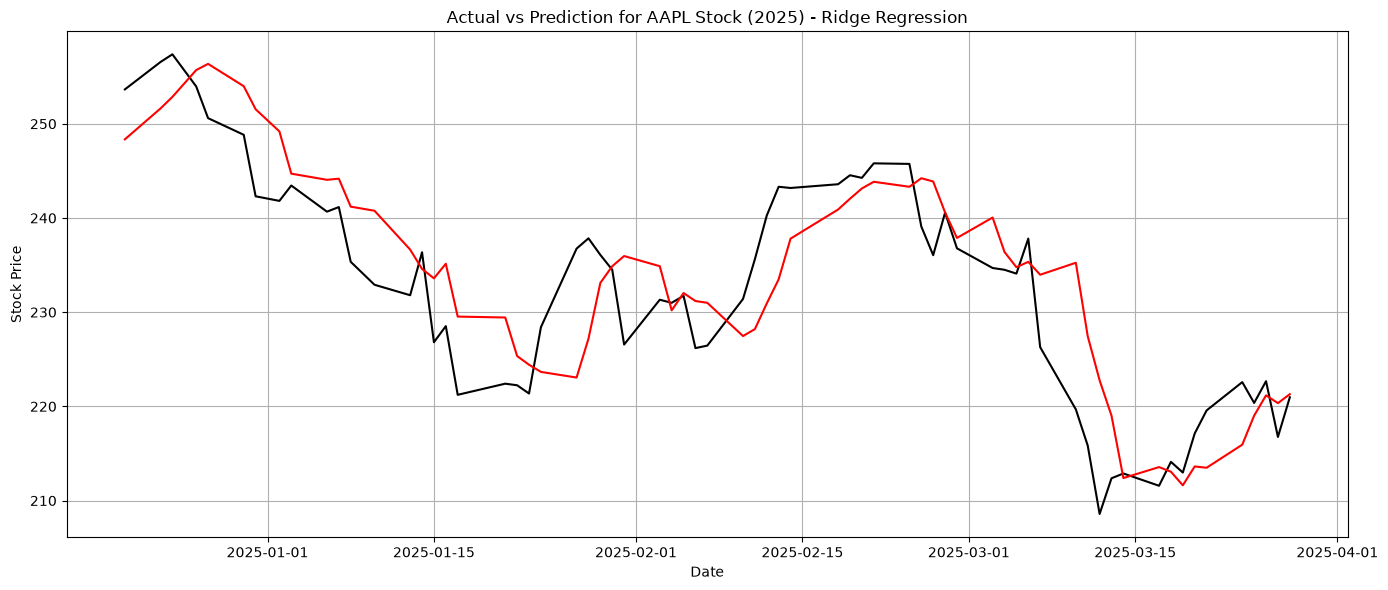

In [26]:
# Step 8: Plot Actual & Predicted Values
import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_result.index, df_result['Actual'], label = 'Actual', color = 'black')
plt.plot(df_result.index, df_result['Predicted'], label = 'Predicted', color = 'red')
plt.title("Actual vs Prediction for AAPL Stock (2025) - Ridge Regression")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.grid(True)
plt.tight_layout()
plt.show()


In [27]:
# Step 9: Evaluate the Model - R square, mse, rmse
from sklearn.metrics import r2_score, mean_squared_error
r2 = r2_score(Y_test, y_pred)
print("R square", r2)
mse = mean_squared_error(Y_test, y_pred)
print("mse",mse)
rmse = np.sqrt(mse)
print("rmse", rmse)


R square 0.7443738818397119
mse 35.77984750522315
rmse 5.98162582457505


In [ ]:
# Elastic Net Regression
# Step 1: Import all the required libraries
# Step 2: Define Features and Target Variables
# Step 3: Train Test Split
# Step 4: Apply Elastic Net Regression
# Step 5: Get Intercept and Coeff for Elastic Net Regression
# Step 6: Predict using Elastic Net Regression
# Step 7: Create a dataframe with Actual and Predicted Values
# Step 8: Plot Actual & Predicted Values
# Step 9: Evaluate the Model - R square, mse, rmse


In [28]:
# Step 1: Import all the required libraries
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

In [29]:
# Step 2: Define Features and Target Variables
X = df[['AAPL(t-1)', 'AMZN(t-1)',
 'MSFT(t-1)', 'QQQ(t-1)', '^GSPC(t-1)', 'AAPL_MA_5', 'AMZN_MA_5','MSFT_MA_5', 'QQQ_MA_5', '^GSPC_MA_5']]
Y = df['Target']




In [30]:
# Step 3: Train Test Split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.05,shuffle = False)

In [32]:
# Step 4: Apply Elastic Net Regression
from sklearn.linear_model import ElasticNet
elastic_net = ElasticNet(alpha = 1, l1_ratio = 0.5)
elastic_net.fit(X_train, Y_train) #Train the model
# alpha = 1, alpha control the strength of regularization
# l1_ratio = 0.5 => applying 50% lasso and 50% as ridge regression

c:\Users\Bhavya\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.405820e+03, tolerance: 2.108e+02
  model = cd_fast.enet_coordinate_descent(


,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",1
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet<sphx_glr_auto_examples_linear_model_plot_elastic_net_precomputed_gram_matrix_with_weighted_samples.py>`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [33]:
# Step 5: Get Intercept and Coeff for Elastic Net Regression
coefficients = elastic_net.coef_
coefficients
intercept = elastic_net.intercept_
intercept
coeff_df = pd.DataFrame({'Feature':X.columns, 'Coefficients':coefficients})
coeff_df


,Feature,Coefficients
0,AAPL(t-1),0.529256
1,AMZN(t-1),0.000309
2,MSFT(t-1),0.010775
3,QQQ(t-1),0.002926
4,^GSPC(t-1),0.006569
5,AAPL_MA_5,0.447938
6,AMZN_MA_5,0.000000
7,MSFT_MA_5,0.000000
8,QQQ_MA_5,0.000000
9,^GSPC_MA_5,-0.006763


In [34]:
# Step 6: Predict using Elastic Net Regression
y_pred = elastic_net.predict(X_test)
y_pred

array([248.20028542, 251.61171109, 252.74060912, 255.53290144,
       256.30934128, 253.79331916, 251.20240473, 249.00581277,
       244.16562306, 243.52097722, 243.77379246, 241.04667442,
       240.82154245, 236.40776033, 234.29187255, 233.28738554,
       235.24170972, 229.23450956, 229.26790605, 224.58743894,
       224.17320654, 223.59558983, 222.9490786 , 227.30774542,
       233.6929894 , 235.33426068, 235.58621621, 234.40750598,
       229.40165187, 231.59723038, 231.18782654, 231.03770669,
       227.52567906, 227.94477407, 230.99054278, 233.81441119,
       238.13548756, 241.14596614, 242.18089297, 243.25207291,
       244.09423307, 243.54270244, 244.56313126, 244.11600275,
       240.21412824, 237.61100552, 240.05563344, 236.48566239,
       234.64813139, 235.11517918, 234.13127527, 235.65810315,
       227.27064209, 222.15346284, 218.35407697, 211.82329622,
       213.45594243, 213.1880632 , 211.76326632, 213.77191134,
       213.46217218, 216.21509079, 218.98599385, 221.17

In [35]:
# Step 7: Create a dataframe with Actual and Predicted Values
df_result = pd.DataFrame({'Actual': Y_test, 'Predicted': y_pred})
df_result


,Actual,Predicted
Date,,
2024-12-20,253.649414,248.200285
2024-12-23,256.560791,251.611711
2024-12-24,257.375580,252.740609
2024-12-26,253.967377,255.532901
2024-12-27,250.598907,256.309341
...,...,...
2025-03-24,222.573975,216.215091
2025-03-25,220.365646,218.985994
2025-03-26,222.673462,221.177309


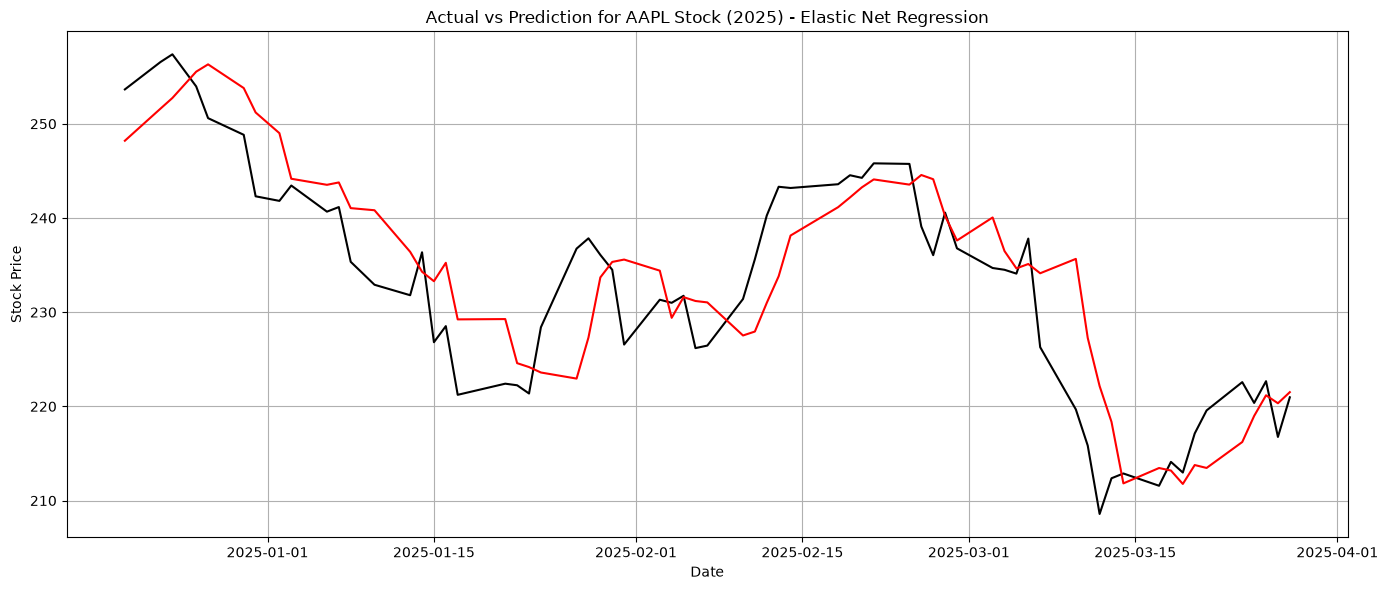

In [36]:
# Step 8: Plot Actual & Predicted Values
import matplotlib.pyplot as plt
plt.figure(figsize = (14,6))
plt.plot(df_result.index, df_result['Actual'], label = 'Actual', color = 'black')
plt.plot(df_result.index, df_result['Predicted'], label = 'Predicted', color = 'red')
plt.title("Actual vs Prediction for AAPL Stock (2025) - Elastic Net Regression")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.grid(True)
plt.tight_layout()
plt.show()


In [37]:
# Step 9: Evaluate the Model - R square, mse, rmse
from sklearn.metrics import r2_score, mean_squared_error
r2 = r2_score(Y_test, y_pred)
print("R square", r2)
mse = mean_squared_error(Y_test, y_pred)
print("mse",mse)
rmse = np.sqrt(mse)
print("rmse", rmse)

R square 0.7513315294371712
mse 34.80598938843997
rmse 5.899660107874009


In [38]:
# Performance for All our Models

# OLS
# R-squared:0.993
# mse 17.35226637043703
# rmse 4.165605162570864

# Lasso Regression
# R square 0.6745742009648297
# mse 33.88523829601259
# rmse 5.82110284190312

# Ridge Regression
# R square 0.6552348986780858
# mse 35.898959606393746
# rmse 5.9915740508145054

# Elastic Net Regression
# R square 0.6638572193358945
# mse 35.0011531294005
# rmse 5.9161772395188175

# Thank You!
